In [ ]:
# Install: pip install tensorflow numpy

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [ ]:
# 1. Training data - AND gate
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=np.float32)

y = np.array([0, 0, 0, 1], dtype=np.float32)

In [ ]:
X.shape,y.shape

((4, 2), (4,))

In [ ]:


# 2. Build a single-layer perceptron
model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(1, activation="sigmoid")
])

# 3. Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Train the model
model.fit(X, y, epochs=500)

# 5. Evaluate
loss, accuracy = model.evaluate(X, y, verbose=0)
print("Training Accuracy:", accuracy)

# 6. Save trained model
model.save("perceptron_model.keras")
print("Model saved successfully!")

# 7. Load saved model
loaded_model = keras.models.load_model(
    "perceptron_model.keras"
)

# 8. New data for inference
new_data = np.array([
    [1, 1],
    [1, 0],
    [0, 1],
    [0, 0]
], dtype=np.float32)

# 9. Predict probabilities
predictions = loaded_model.predict(new_data, verbose=0)

# 10. Convert probabilities to classes
classes = (predictions >= 0.5).astype(int)

for inputs, probability, output in zip(
    new_data, predictions, classes
):
    print(
        f"Input: {inputs.astype(int)} "
        f"Probability: {probability[0]:.4f} "
        f"Prediction: {output[0]}"
    )


Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 662ms/step - accuracy: 0.5000 - loss: 0.7410
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5000 - loss: 0.6915
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.6528
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.6248
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7500 - loss: 0.6060
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.5928
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7500 - loss: 0.5818
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.5707
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.5585
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7500 - loss: 0.5451
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7500 - loss: 0.5308
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7500 - l

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=np.float32)

y = np.array([
    [0],
    [0],
    [0],
    [1]
], dtype=np.float32)

model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(3, activation="sigmoid"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

model.fit(
    X,
    y,
    epochs=500,
    batch_size=4,
    verbose=0
)

loss, accuracy = model.evaluate(X, y, verbose=0)

print("Loss:", loss)
print("Accuracy:", accuracy)

model.save("perceptron_3_neurons.keras")

loaded_model = keras.models.load_model(
    "perceptron_3_neurons.keras"
)

new_data = np.array([
    [1, 1],
    [0, 0],
    [1, 0],
    [0, 1]
], dtype=np.float32)

predictions = loaded_model.predict(new_data, verbose=0)

classes = (predictions >= 0.5).astype(int)

print("Predictions:")
print(classes)

for inputs, probability, output in zip(
    new_data, predictions, classes
):
    print(inputs.astype(int), probability[0], output[0])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

Loss: 0.0015360404504463077
Accuracy: 1.0
Predictions:
[[1]
 [0]
 [0]
 [0]]
[1 1] 0.99672437 1
[0 0] 3.1321964e-05 0
[1 0] 0.0021406482 0
[0 1] 0.00068865006 0


In [ ]:
loss, accuracy

(0.0015360404504463077, 1.0)

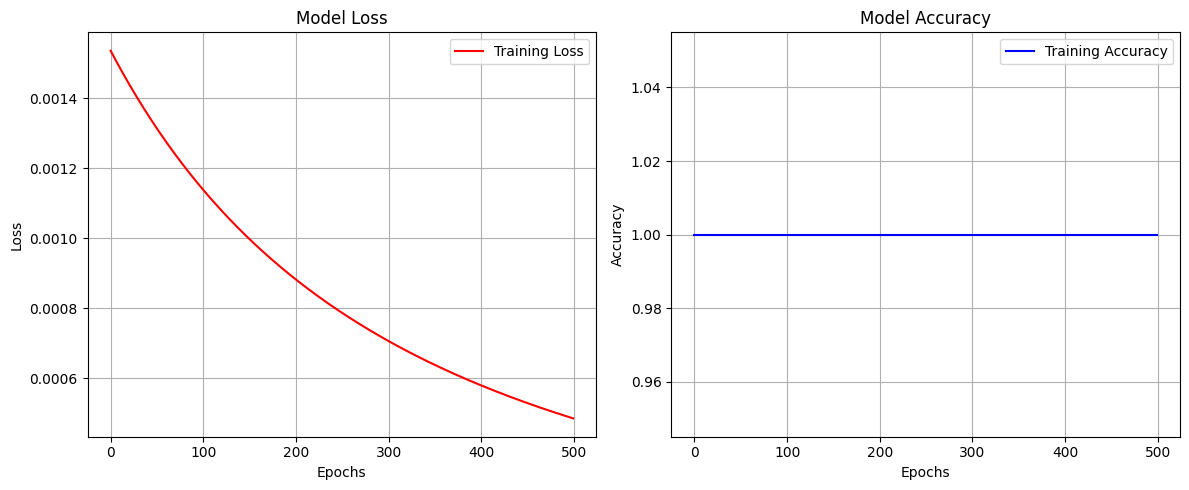

In [ ]:

import matplotlib.pyplot as plt

history = model.fit(
    X,
    y,
    epochs=500,
    batch_size=4,
    verbose=0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], color="red", label="Training Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], color="blue", label="Training Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28 (112.00 B)

 Trainable params: 28 (112.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4991 - loss: 0.8315 - val_accuracy: 0.6294 - val_loss: 0.8487
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6063 - loss: 0.7862 - val_accuracy: 0.6853 - val_loss: 0.8094
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6749 - loss: 0.7471 - val_accuracy: 0.7133 - val_loss: 0.7759
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6960 - loss: 0.7147 - val_accuracy: 0.7203 - val_loss: 0.7490
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7223 - loss: 0.6879 - val_accuracy: 0.7552 - val_loss: 0.7246
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7223 - loss: 0.6634 - val_accuracy: 0.7552 - val_loss: 0.7025
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7381 - loss: 0.6413 - val_accuracy: 0.7552 - val_loss: 0.6827
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7469 - loss: 0.6218 - val_accuracy: 0.7413 - v

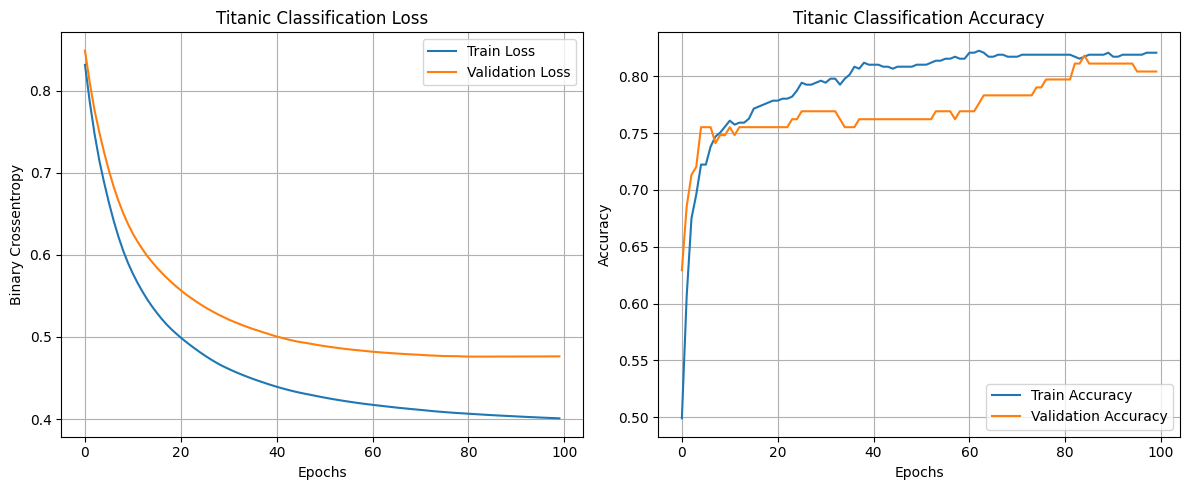

Survival Probability: 0.9916135
Predicted Class: 1


In [ ]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

keras.utils.set_random_seed(42)

df = sns.load_dataset("titanic")

X = df[[
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked"
]].copy()

y = df[["survived"]]

X["sex"] = X["sex"].map({
    "male": 0,
    "female": 1
})

X["embarked"] = X["embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    keras.Input(shape=(7,)),
    layers.Dense(3, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

loss, accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Titanic Classification Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Crossentropy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Titanic Classification Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

model.save("titanic_classification.keras")

joblib.dump(
    (imputer, scaler),
    "classification_preprocessing.pkl"
)

loaded_model = keras.models.load_model(
    "titanic_classification.keras"
)

new_data = pd.DataFrame([{
    "pclass": 1,
    "sex": 1,
    "age": 30,
    "sibsp": 0,
    "parch": 0,
    "fare": 80,
    "embarked": 1
}])

saved_imputer, saved_scaler = joblib.load(
    "classification_preprocessing.pkl"
)

new_data = saved_imputer.transform(new_data)
new_data = saved_scaler.transform(new_data)

prediction = loaded_model.predict(new_data, verbose=0)

print("Survival Probability:", prediction[0][0])
print("Predicted Class:", int(prediction[0][0] >= 0.5))


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4077 - loss: 0.8365 - val_accuracy: 0.4196 - val_loss: 0.8198
Epoch 2/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4112 - loss: 0.7762 - val_accuracy: 0.4545 - val_loss: 0.7693
Epoch 3/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.4552 - loss: 0.7318 - val_accuracy: 0.5385 - val_loss: 0.7327
Epoch 4/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5325 - loss: 0.6989 - val_accuracy: 0.6713 - val_loss: 0.7061
Epoch 5/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7065 - loss: 0.6747 - val_accuracy: 0.7203 - val_loss: 0.6853
Epoch 6/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7170 - loss: 0.6555 - val_accuracy: 0.7133 - val_loss: 0.6685
Epoch 7/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7223 - loss: 0.6395 - val_accuracy: 0.7133 - val_loss: 0.6542
Epoch 8/1000
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7258 - loss: 0.6254 - val_accura

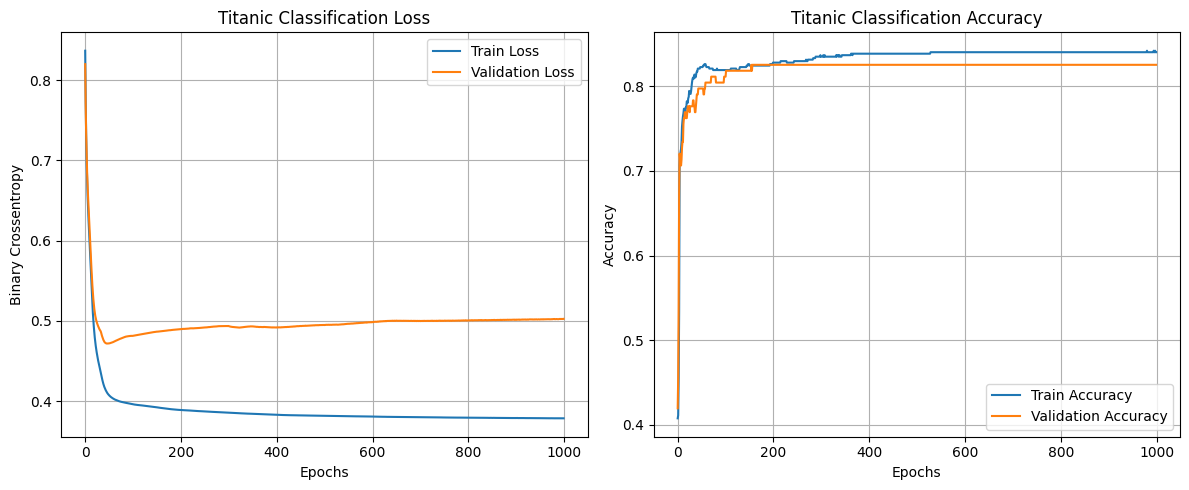

Survival Probability: 0.99881387
Predicted Class: 1


In [ ]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

keras.utils.set_random_seed(42)

df = sns.load_dataset("titanic")

X = df[[
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked"
]].copy()

y = df[["survived"]]

X["sex"] = X["sex"].map({
    "male": 0,
    "female": 1
})

X["embarked"] = X["embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    keras.Input(shape=(7,)),
    layers.Dense(3, activation="relu"),
    layers.Dense(3, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

loss, accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Titanic Classification Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Crossentropy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Titanic Classification Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

model.save("titanic_classification_2hidden.keras")

joblib.dump(
    (imputer, scaler),
    "classification_preprocessing.pkl"
)

loaded_model = keras.models.load_model(
    "titanic_classification_2hidden.keras"
)

new_data = pd.DataFrame([{
    "pclass": 1,
    "sex": 1,
    "age": 30,
    "sibsp": 0,
    "parch": 0,
    "fare": 80,
    "embarked": 1
}])

saved_imputer, saved_scaler = joblib.load(
    "classification_preprocessing.pkl"
)

new_data = saved_imputer.transform(new_data)
new_data = saved_scaler.transform(new_data)

prediction = loaded_model.predict(new_data, verbose=0)

print("Survival Probability:", prediction[0][0])
print("Predicted Class:", int(prediction[0][0] >= 0.5))


   Product_Price  Quantity  Discount  Advertising_Spend  Store_Footfall  \
0           1226        34        11               3811             103   
1           1559        74        11               8098             107   
2            960        62        19               7546             372   
3           1394        14        29               2986             409   
4           1230        95        29               9338             223   
5           1195        48        10               3911             329   
6           1824        15        25               2734             163   
7           1144        72        22               2843             337   
8           1738        78        27               9680             480   
9            221        87        24               3976             391   

   Sales_Revenue  
0   38576.505539  
1  103360.832166  
2   48935.385660  
3   14801.395468  
4   84435.227757  
5   52962.048568  
6   22186.720624  
7   65318.764411  
8  

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 8)              │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

MAE: 8586.4248046875
RMSE: 12391.107779371463
R2 Score: 0.9169776439666748


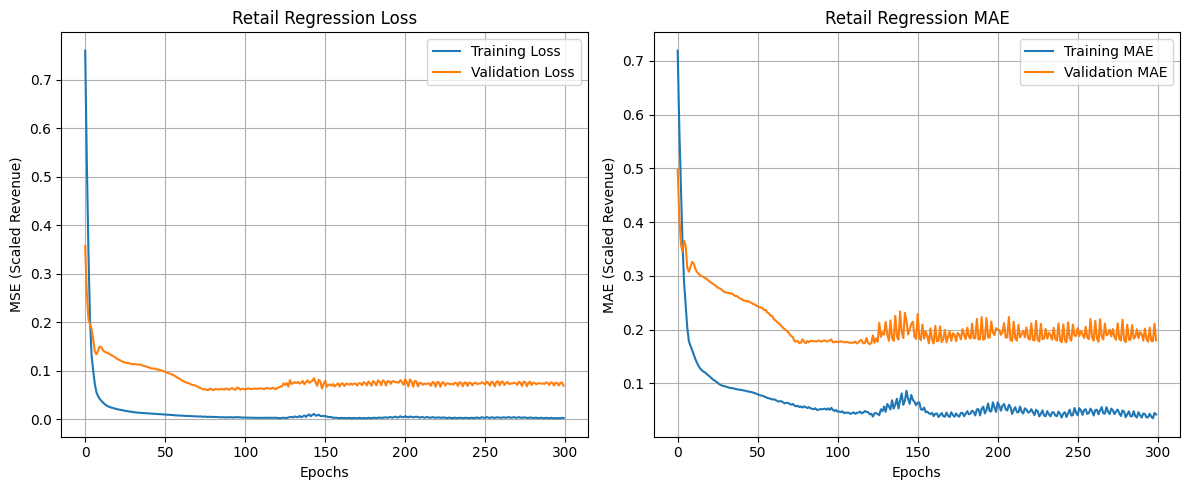

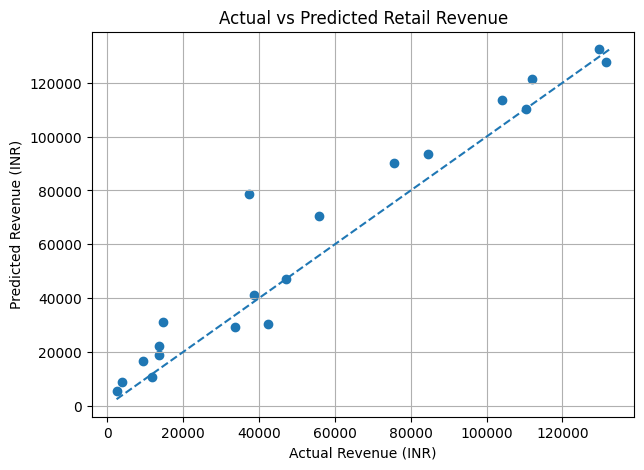

Predicted Sales Revenue: INR 31533.037


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

np.random.seed(42)
keras.utils.set_random_seed(42)

# Generate 100 retail records
n = 100

df = pd.DataFrame({
    "Product_Price": np.random.randint(100, 2000, n),
    "Quantity": np.random.randint(1, 100, n),
    "Discount": np.random.randint(0, 31, n),
    "Advertising_Spend": np.random.randint(1000, 10000, n),
    "Store_Footfall": np.random.randint(50, 500, n)
})

# Calculate sales revenue with small random noise
df["Sales_Revenue"] = (
    df["Product_Price"]
    * df["Quantity"]
    * (1 - df["Discount"] / 100)
    + 0.1 * df["Advertising_Spend"]
    + 2 * df["Store_Footfall"]
    + np.random.normal(0, 500, n)
)

df["Sales_Revenue"] = df["Sales_Revenue"].clip(lower=0)

print(df.head(10))
print("Dataset Shape:", df.shape)

df.to_csv("retail_sales_100.csv", index=False)

# Input features and target
X = df.drop("Sales_Revenue", axis=1)
y = df[["Sales_Revenue"]]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale input features
scaler_X = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

# Scale target values
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# Build regression neural network
model = keras.Sequential([
    keras.Input(shape=(5,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="linear")
])

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

model.summary()

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=300,
    batch_size=8,
    validation_split=0.2,
    verbose=0
)

# Predict on test data
predictions_scaled = model.predict(X_test, verbose=0)

# Convert predictions to original rupee scale
predictions = scaler_y.inverse_transform(
    predictions_scaled
)

# Evaluate model
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

# Draw loss and MAE graphs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Retail Regression Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE (Scaled Revenue)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    history.history["mae"],
    label="Training MAE"
)

plt.plot(
    history.history["val_mae"],
    label="Validation MAE"
)

plt.title("Retail Regression MAE")
plt.xlabel("Epochs")
plt.ylabel("MAE (Scaled Revenue)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Actual vs predicted revenue
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test.values.ravel(),
    predictions.ravel()
)

min_val = min(y_test.min().iloc[0], predictions.min())
max_val = max(y_test.max().iloc[0], predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.title("Actual vs Predicted Retail Revenue")
plt.xlabel("Actual Revenue (INR)")
plt.ylabel("Predicted Revenue (INR)")
plt.grid(True)
plt.show()

# Save model and scalers
model.save("retail_regression_model.keras")

joblib.dump(
    (scaler_X, scaler_y, list(X.columns)),
    "retail_scalers.pkl"
)

# Load model
loaded_model = keras.models.load_model(
    "retail_regression_model.keras"
)

loaded_scaler_X, loaded_scaler_y, feature_names = joblib.load(
    "retail_scalers.pkl"
)

# New retail data
new_data = pd.DataFrame([{
    "Product_Price": 1200,
    "Quantity": 25,
    "Discount": 10,
    "Advertising_Spend": 5000,
    "Store_Footfall": 200
}])

# Preprocess new data
new_scaled = loaded_scaler_X.transform(
    new_data[feature_names]
)

# Run inference
prediction_scaled = loaded_model.predict(
    new_scaled,
    verbose=0
)

prediction = loaded_scaler_y.inverse_transform(
    prediction_scaled
)

print("Predicted Sales Revenue: INR", prediction[0][0])


sentiment analysis

	1.Extract hashtags from twitter for a brand
	2.Sentiment Analysis:
		x,y ( Positive, neutral,negative)
		x: tweet
		y: SME , Predefined model
	3.Preprocessing
	4.Model network building
		1.building from scratch
			5 layers
			11 nodes
			1 output layer
		2.Save the model in pickle
		2. Build the model using transfer leanring
			import a model from hugging face
			update the model training weights

	5. Draw the model loss and accuracy graph
	6. Predict the sentiment from new observations
	7. Model finetuning
	9. Model monitoring and deployment